# Day 2 · 05 — Lab: hierarchy and coherence (20 min)

The store plans at several levels: total → department → class → subclass → item. Forecasts made
independently at each level do **not add up**. Reconciliation makes them coherent; the question is which
method, and what it costs or gains at each level.

| Method | Idea |
|---|---|
| `BottomUp` | forecast items, sum upwards |
| `TopDown` (forecast proportions) | forecast the total, split it down |
| `MiddleOut` (class) | forecast a middle level, sum up and split down |
| `MinTrace` `ols` / `wls_struct` / `mint_shrink` | least-squares adjustment of all levels at once, weighted by (estimated) error covariance |

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl

import bootcamp as bc

warnings.filterwarnings("ignore")
palette = ["#000000", "#0072B2", "#D55E00", "#009E73", "#CC79A7", "#56B4E9", "#E69F00"]
plt.rcParams.update({"figure.figsize": (12, 5), "axes.prop_cycle": plt.cycler(color=palette)})

/home/user/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Intuition: the numbers must add up

![Incoherent forecasts](slides/img/hierarchy_tree.png)

Forecast every level separately and the items will not add up to the department, like a budget whose line
items disagree with its total. Reconciliation decides **whom to believe**:

* **BottomUp** trusts the items and sums them.
* **TopDown** trusts the total and splits it by historical proportions.
* **MinTrace** trusts each level in proportion to how reliable it has been, and moves every number as little as
  possible to make them add up.

## 1. Build the hierarchy

`hierarchy.csv` maps subclass → class → department. Items without a subclass (448 in the full data) cannot
be placed and are dropped from this lab.

In [2]:
from hierarchicalforecast.utils import aggregate

panel = bc.load_panel().filter(pl.col("subclass_id") > 0)
hier = pl.read_csv(bc.DATA_DIR / "hierarchy.csv")

df = panel.select(
    pl.lit("Total").alias("total"),
    pl.format("D{}", pl.col("department_id")).alias("department"),
    pl.format("C{}", pl.col("class_id")).alias("class"),
    pl.format("S{}", pl.col("subclass_id")).alias("subclass"),
    pl.col("unique_id").alias("item"),
    "ds", "y",
).to_pandas()
df["ds"] = pd.to_datetime(df["ds"])

spec = [
    ["total"],
    ["total", "department"],
    ["total", "department", "class"],
    ["total", "department", "class", "subclass"],
    ["total", "department", "class", "subclass", "item"],
]
Y_df, S_df, tags = aggregate(df, spec)
print({k.split("/")[-1]: len(v) for k, v in tags.items()})

test_start = pd.Timestamp(bc.TEST_START)
Y_train = Y_df[Y_df.ds < test_start]
Y_test = Y_df[Y_df.ds >= test_start]

{'total': 1, 'department': 125, 'class': 344, 'subclass': 772, 'item': 1997}


## 2. Base forecasts at every level

AutoETS for every node (fast, decent at aggregate levels), with in-sample fitted values, which `MinTrace`
needs to estimate the error covariance.

In [3]:
from statsforecast import StatsForecast
from statsforecast.models import AutoETS, Naive

sf = StatsForecast(models=[AutoETS(season_length=1)], freq=bc.FREQ, n_jobs=-1, fallback_model=Naive())
with bc.Timer() as t_base:
    Y_hat = sf.forecast(df=Y_train, h=bc.H, fitted=True)
Y_fitted = sf.forecast_fitted_values()
print(f"{Y_hat.unique_id.nunique():,} nodes forecast in {t_base.seconds:.0f}s")

3,239 nodes forecast in 4s


## 3. Reconcile

In [4]:
from hierarchicalforecast.core import HierarchicalReconciliation
from hierarchicalforecast.methods import BottomUp, MiddleOut, MinTrace, TopDown

reconcilers = [
    BottomUp(),
    TopDown(method="forecast_proportions"),
    MiddleOut(middle_level="total/department/class", top_down_method="forecast_proportions"),
    MinTrace(method="ols"),
    MinTrace(method="wls_struct"),
    MinTrace(method="mint_shrink"),
]
hrec = HierarchicalReconciliation(reconcilers=reconcilers)
with bc.Timer() as t_rec:
    Y_rec = hrec.reconcile(Y_hat_df=Y_hat, Y_df=Y_fitted, S_df=S_df, tags=tags)
print(f"reconciled in {t_rec.seconds:.1f}s")
methods = [c for c in Y_rec.columns if c.startswith("AutoETS")]
SHORT = {"AutoETS": "Base (incoherent)", "AutoETS/BottomUp": "BottomUp",
         "AutoETS/TopDown_method-forecast_proportions": "TopDown",
         "AutoETS/MiddleOut_middle_level-total/department/class_top_down_method-forecast_proportions": "MiddleOut(class)",
         "AutoETS/MinTrace_method-ols": "MinT-ols", "AutoETS/MinTrace_method-wls_struct": "MinT-wls_struct",
         "AutoETS/MinTrace_method-mint_shrink": "MinT-shrink"}
Y_rec = Y_rec.rename(columns=SHORT)
methods = [SHORT.get(c, c) for c in methods]
methods

reconciled in 30.1s


['Base (incoherent)',
 'BottomUp',
 'TopDown',
 'MiddleOut(class)',
 'MinT-ols',
 'MinT-wls_struct',
 'MinT-shrink']

### Coherence check: do the items sum to the total?

In [5]:
items = tags["total/department/class/subclass/item"]
chk = {}
for m in methods:
    tot = Y_rec[Y_rec.unique_id == "Total"].set_index("ds")[m]
    bottom = Y_rec[Y_rec.unique_id.isin(items)].groupby("ds")[m].sum()
    chk[m] = float((tot - bottom).abs().max())
pd.Series(chk, name="max |total − Σ items|").round(2)

Base (incoherent)    379017.68
BottomUp                  0.00
TopDown                   0.00
MiddleOut(class)     285452.68
MinT-ols                  0.00
MinT-wls_struct           0.00
MinT-shrink               0.00
Name: max |total − Σ items|, dtype: float64

## 4. Accuracy per level

Scaled errors (RMSSE against a 1-step naive, because aggregates have <2 years of history) so levels are
comparable. The question is not "which method wins" but **"where does each method pay"**.

In [6]:
from functools import partial

from utilsforecast.evaluation import evaluate
from utilsforecast.losses import rmsse

ev = evaluate(Y_rec.merge(Y_test, on=["unique_id", "ds"]), metrics=[partial(rmsse, seasonality=1)],
              models=methods, train_df=Y_train)
ev["metric"] = "rmsse"
level_of = {uid: lvl.split("/")[-1] for lvl, uids in tags.items() for uid in uids}
ev["level"] = ev.unique_id.map(level_of)
by_level = ev.groupby("level")[methods].mean().loc[["total", "department", "class", "subclass", "item"]]
by_level.round(3)

,Base (incoherent),BottomUp,TopDown,MiddleOut(class),MinT-ols,MinT-wls_struct,MinT-shrink
level,,,,,,,
total,0.885,1.143,0.885,1.145,0.887,1.059,1.103
department,1.086,1.073,1.071,1.094,2.933,1.135,1.054
class,1.197,1.176,1.206,1.338,4.478,1.439,1.169
subclass,1.429,1.411,1.460,1.524,5.857,1.954,1.398
item,1.898,1.898,2.089,2.151,10.892,4.912,1.897


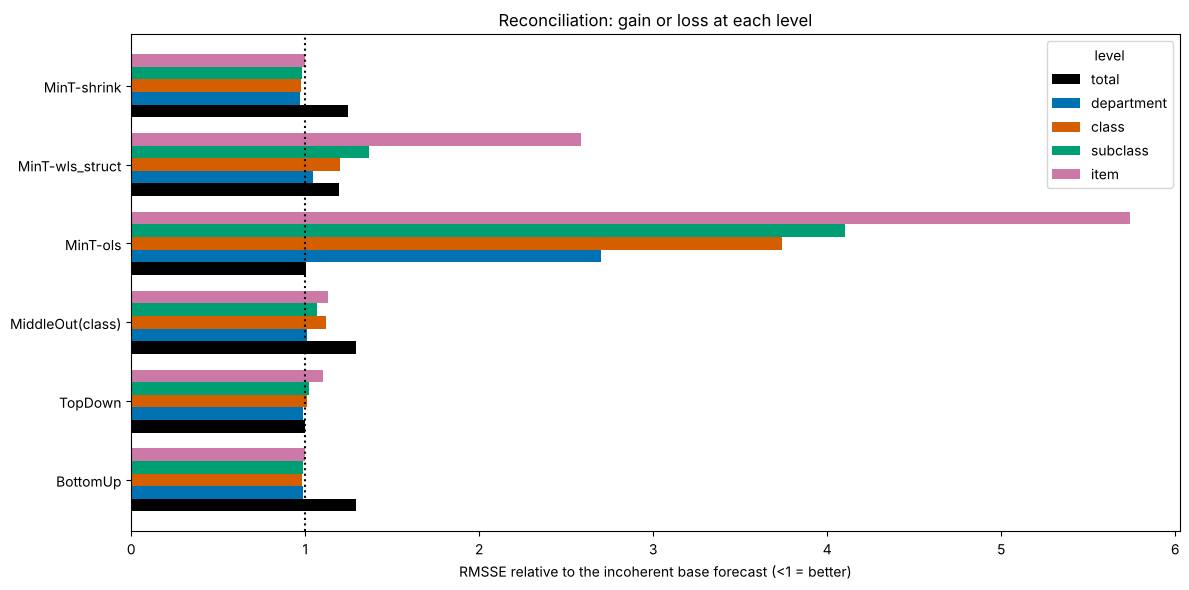

In [7]:
rel = by_level.div(by_level["Base (incoherent)"], axis=0)
ax = rel.drop(columns="Base (incoherent)").T.plot.barh(figsize=(12, 6), width=0.8)
ax.axvline(1, color="black", ls=":")
ax.set_xlabel("RMSSE relative to the incoherent base forecast (<1 = better)")
ax.set_title("Reconciliation: gain or loss at each level")
plt.tight_layout()

### Reading the result

![Lab 05 results](slides/img/res_lab05.png)

In the reference run (ratios to the incoherent base forecasts):

* **BottomUp**: items unchanged, total ≈ 29 % worse. Small item biases add up across 2,000 items.
* **TopDown**: total unchanged, items ≈ 10 % worse. Fixed proportions miss item-level promotions.
* **MinT-shrink**: within a few percent of the best at every level, and coherent.
* **MinT-ols** is 3–11× worse below the total: it treats a 600-unit item and a 150k-unit department as equally
  reliable. The weights are the whole point.

*Reference run: 2,000 series, laptop CPU, 500 steps. Your numbers will differ a little; the reading should not.*

## 5. Item level onto the leaderboard

The item level is the leaderboard level, so the reconciled item forecasts can be compared with every other
model today. Add the best method.

In [8]:
train_pl, test_pl = bc.split(panel)
item_fc = Y_rec[Y_rec.unique_id.isin(items)][["unique_id", "ds"] + methods].copy()
item_fc["unique_id"] = item_fc["unique_id"].str.split("/").str[-1]    # "Total/D…/C…/S…/123_S1" → "123_S1"
# Base and BottomUp item forecasts are identical to AutoETS from notebook 00, so only the
# methods that change the item level go on the leaderboard.
item_fc = item_fc.rename(columns={"TopDown": "ETS_TopDown", "MinT-wls_struct": "ETS_MinT-wls",
                                  "MinT-shrink": "ETS_MinT-shrink"})
keep = ["unique_id", "ds", "ETS_TopDown", "ETS_MinT-wls", "ETS_MinT-shrink"]
bc.save_forecasts(item_fc[keep], "05_hierarchy")
bc.record(item_fc[keep], test_pl, train_pl, lab="05 hierarchy",
          fit_seconds=t_base.seconds + t_rec.seconds)

,model,mean_rmsse,median_rmsse,mean_mase,mean_smape,n_series,wape,lab,fit_seconds,notes,recorded_at
0,ETS_MinT-shrink,1.250654,0.709792,2.841887,0.300996,1996,0.423730,05 hierarchy,34.014993,,2026-10-27 22:11:51
1,ETS_TopDown,1.319786,0.726565,2.877396,0.317549,1996,0.436526,05 hierarchy,34.014993,,2026-10-27 22:11:51
2,ETS_MinT-wls,1.812600,0.772612,4.034624,0.347338,1996,0.434354,05 hierarchy,34.014993,,2026-10-27 22:11:51


## Discussion

* BottomUp is free at the item level and usually poor at the top. TopDown is the reverse. Who consumes which
  level in the business?
* `mint_shrink` needs a covariance estimate across thousands of nodes from ~90 weeks of residuals; that is
  what the shrinkage is for. When does `wls_struct` (no covariance at all) do just as well?
* Swap the base model for a global model (e.g. LightGBM from Day 1) at the item level and keep ETS above.
  Reconciliation does not care where base forecasts come from.